## 1. Import libraries and prepare the model

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 120)

### Training data
The model uses the four numeric features specified in the lab manual: `failed_logins`, `login_hour`, `new_device`, and `download_mb`. The labels are illustrative Normal/Suspicious examples.

In [ ]:
training_data = pd.DataFrame([
    [0, 10, 0, 40, 'Normal'],
    [1, 15, 0, 80, 'Normal'],
    [2, 9, 0, 80, 'Normal'],
    [0, 14, 0, 120, 'Normal'],
    [1, 20, 0, 60, 'Normal'],
    [3, 11, 0, 150, 'Normal'],
    [2, 2, 1, 150, 'Suspicious'],
    [7, 2, 1, 150, 'Suspicious'],
    [4, 23, 1, 400, 'Suspicious'],
    [6, 1, 0, 600, 'Suspicious'],
    [1, 3, 1, 720, 'Suspicious'],
    [5, 18, 1, 550, 'Suspicious'],
    [0, 8, 0, 700, 'Suspicious'],
    [3, 23, 1, 100, 'Suspicious'],
], columns=['failed_logins', 'login_hour', 'new_device', 'download_mb', 'label'])

features = ['failed_logins', 'login_hour', 'new_device', 'download_mb']
X_train = training_data[features]
y_train = training_data['label']

model = DecisionTreeClassifier(max_depth=4, random_state=42)
model.fit(X_train, y_train)

print('Decision Tree model trained successfully.')
print('Classes:', list(model.classes_))
display(training_data.head())

Decision Tree model trained successfully.
Classes: ['Normal', 'Suspicious']


,failed_logins,login_hour,new_device,download_mb,label
0,0,10,0,40,Normal
1,1,15,0,80,Normal
2,2,9,0,80,Normal
3,0,14,0,120,Normal
4,1,20,0,60,Normal


## 2. Q1 – Baseline Predictions with Confidence (5 Marks)

**Aim:** Run the model on five sanitized records and display the prediction with confidence. Confidence is the maximum predicted class probability; it supports, but does not replace, human judgement.

In [ ]:
samples = pd.DataFrame([
    {'account_id': 'ACC-1001', 'ip_address': '192.168.10.24',
     'failed_logins': 0, 'login_hour': 10,
     'new_device': 0, 'download_mb': 40},
    {'account_id': 'ACC-1002', 'ip_address': '10.0.4.18',
     'failed_logins': 7, 'login_hour': 2,
     'new_device': 1, 'download_mb': 150},
    {'account_id': 'ACC-1003', 'ip_address': '172.16.8.90',
     'failed_logins': 1, 'login_hour': 15,
     'new_device': 0, 'download_mb': 720},
    {'account_id': 'ACC-1004', 'ip_address': '192.168.20.11',
     'failed_logins': 4, 'login_hour': 23,
     'new_device': 1, 'download_mb': 400},
    {'account_id': 'ACC-1005', 'ip_address': '10.1.1.9',
     'failed_logins': 2, 'login_hour': 9,
     'new_device': 0, 'download_mb': 80}
])

samples['prediction'] = model.predict(samples[features])
samples['confidence'] = model.predict_proba(samples[features]).max(axis=1).round(3)

display(samples)

,account_id,ip_address,failed_logins,login_hour,new_device,download_mb,prediction,confidence
0,ACC-1001,192.168.10.24,0,10,0,40,Normal,1.0
1,ACC-1002,10.0.4.18,7,2,1,150,Suspicious,1.0
2,ACC-1003,172.16.8.90,1,15,0,720,Suspicious,1.0
3,ACC-1004,192.168.20.11,4,23,1,400,Suspicious,1.0
4,ACC-1005,10.1.1.9,2,9,0,80,Normal,1.0


In [ ]:
lowest_confidence_row = samples.loc[samples['confidence'].idxmin()]
print('Lowest-confidence record:', lowest_confidence_row['account_id'])
print('Confidence:', lowest_confidence_row['confidence'])

Lowest-confidence record: ACC-1001
Confidence: 1.0


**Observation:** Confidence is not certainty because it is a model-estimated probability based on the training examples and learned decision boundaries. It may be wrong, especially when real activity differs from the training data.

## 3. Q2 – Feature Importance and Explanation (10 Marks)

**Aim:** Display model feature importance, plot a labelled bar chart, and explain the top three features. Feature importance describes how the model uses inputs; it does not prove cause.

,feature,importance
2,new_device,0.5625
3,download_mb,0.4375
1,login_hour,0.0000
0,failed_logins,0.0000


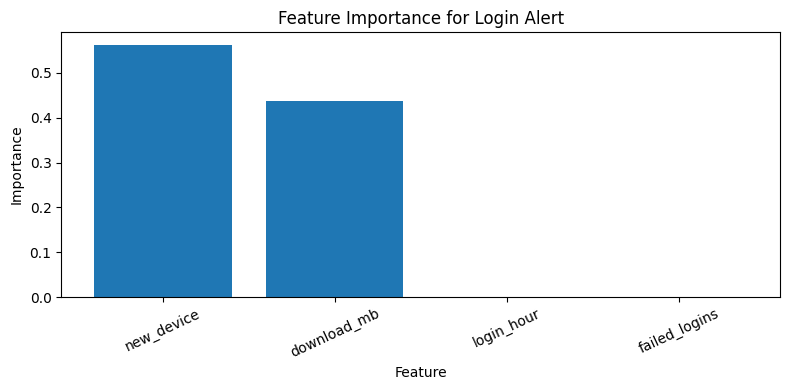

In [ ]:
importance = pd.DataFrame({
    'feature': features,
    'importance': model.feature_importances_
}).sort_values('importance', ascending=False)

display(importance)

plt.figure(figsize=(8, 4))
plt.bar(importance['feature'], importance['importance'])
plt.title('Feature Importance for Login Alert')
plt.ylabel('Importance')
plt.xlabel('Feature')
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

In [ ]:
print('Top-three feature explanations:')
for feature in importance.head(3)['feature']:
    print(f'- {feature} was frequently used by the model to separate records.')

Top-three feature explanations:
- new_device was frequently used by the model to separate records.
- download_mb was frequently used by the model to separate records.
- login_hour was frequently used by the model to separate records.


**Caution:** Feature importance is a model-level explanation, not proof that a feature caused a login to be suspicious.

## 4. Q3 – Controlled Sensitivity Test (10 Marks)

**Aim:** Change exactly one safe numeric input, keep all other inputs fixed, and compare the old and new prediction and confidence. As directed in the manual, change `failed_logins` from 2 to 8 for the fifth sample.

In [ ]:
baseline = samples.iloc[[4]][features].copy()
changed = baseline.copy()
changed['failed_logins'] = 8

baseline_prediction = model.predict(baseline)[0]
baseline_confidence = model.predict_proba(baseline).max()

changed_prediction = model.predict(changed)[0]
changed_confidence = model.predict_proba(changed).max()

sensitivity_results = pd.DataFrame([
    {'case': 'Baseline', 'failed_logins': int(baseline.iloc[0]['failed_logins']),
     'prediction': baseline_prediction, 'confidence': round(baseline_confidence, 3)},
    {'case': 'Changed', 'failed_logins': int(changed.iloc[0]['failed_logins']),
     'prediction': changed_prediction, 'confidence': round(changed_confidence, 3)}
])

display(sensitivity_results)

,case,failed_logins,prediction,confidence
0,Baseline,2,Normal,1.0
1,Changed,8,Normal,1.0


**Sensitivity interpretation:** Only `failed_logins` was changed; the other three features remained fixed. The before-and-after table shows whether this input change altered the model's decision or confidence. A change demonstrates sensitivity to this feature for this particular record. A surprising or unstable result should be reviewed rather than treated as a definitive security finding.

## 5. Q4 – Privacy Masking and Responsible-Use Rules (5 Marks)

**Aim:** Mask the last two IP sections and most of each account ID before display or export.

In [ ]:
def mask_ip(ip):
    parts = str(ip).split('.')
    if len(parts) == 4:
        return f'{parts[0]}.{parts[1]}.xxx.xxx'
    return '<MASKED_IP>'

def mask_account(account_id):
    text = str(account_id)
    return text[:4] + '***' + text[-2:]

samples['masked_ip'] = samples['ip_address'].apply(mask_ip)
samples['masked_account'] = samples['account_id'].apply(mask_account)

# Display only masked identifiers; do not expose raw account IDs or IP addresses.
display(samples[[
    'masked_account', 'masked_ip', 'prediction', 'confidence'
]])

,masked_account,masked_ip,prediction,confidence
0,ACC-***01,192.168.xxx.xxx,Normal,1.0
1,ACC-***02,10.0.xxx.xxx,Suspicious,1.0
2,ACC-***03,172.16.xxx.xxx,Suspicious,1.0
3,ACC-***04,192.168.xxx.xxx,Suspicious,1.0
4,ACC-***05,10.1.xxx.xxx,Normal,1.0


In [ ]:
privacy_rules = [
    'Mask identifiers before display or export.',
    'Use sanitized data in classroom notebooks.',
    'Restrict access to unmasked records.',
    'Require human review for high-risk action.'
]

for rule in privacy_rules:
    print('-', rule)

- Mask identifiers before display or export.
- Use sanitized data in classroom notebooks.
- Restrict access to unmasked records.
- Require human review for high-risk action.


**Privacy observation:** The displayed table uses masked account IDs and IP addresses. Raw identifiers should not appear in screenshots or exported reports; access to unmasked records should be restricted to authorized personnel.

## 6. Q5 – Responsible Alert Generation (10 Marks)

**Aim:** Generate a final alert containing severity, reason, recommended action, and human-review status. This classroom prototype must not automatically punish users or block accounts.

In [ ]:
def numeric_reason(row):
    reasons = []
    if row['failed_logins'] >= 5:
        reasons.append('many failed logins')
    if row['new_device'] == 1:
        reasons.append('new device')
    if row['login_hour'] < 6 or row['login_hour'] > 22:
        reasons.append('unusual login time')
    if row['download_mb'] >= 500:
        reasons.append('large data download')
    return ', '.join(reasons) if reasons else 'no strong warning'

def make_alert(row):
    reason = numeric_reason(row)

    if row['prediction'] == 'Suspicious':
        severity = 'High'
        action = 'Verify, contain if required, and report.'
    elif row['confidence'] < 0.70:
        severity = 'Medium'
        action = 'Send for analyst review before action.'
    else:
        severity = 'Low'
        action = 'Continue normal monitoring.'

    human_review = 'Yes' if severity in ['High', 'Medium'] else 'No'
    return severity, reason, action, human_review

alerts = samples.apply(make_alert, axis=1)

samples[['severity', 'reason', 'recommended_action', 'human_review']] = pd.DataFrame(
    alerts.tolist(), index=samples.index
)

display(samples[[
    'masked_account', 'prediction', 'confidence',
    'severity', 'reason', 'recommended_action', 'human_review'
]])

,masked_account,prediction,confidence,severity,reason,recommended_action,human_review
0,ACC-***01,Normal,1.0,Low,no strong warning,Continue normal monitoring.,No
1,ACC-***02,Suspicious,1.0,High,"many failed logins, new device, unusual login ...","Verify, contain if required, and report.",Yes
2,ACC-***03,Suspicious,1.0,High,large data download,"Verify, contain if required, and report.",Yes
3,ACC-***04,Suspicious,1.0,High,"new device, unusual login time","Verify, contain if required, and report.",Yes
4,ACC-***05,Normal,1.0,Low,no strong warning,Continue normal monitoring.,No


**Alert interpretation:** Suspicious predictions are assigned High severity and sent for verification. Low-confidence cases that are not classified as Suspicious receive Medium severity and analyst review. Low-severity cases continue normal monitoring. Human review is required for High and Medium alerts.

## 7. Conclusion

In this lab, a Decision Tree model was used to classify login activity as Normal or Suspicious and calculate prediction confidence. Feature importance was used to interpret the model, and a controlled change to `failed_logins` demonstrated sensitivity analysis. Account IDs and IP addresses were masked before display. Finally, responsible alerts were generated with severity, reasons, recommended actions, and human-review status.

**Limitation:** This is a small illustrative classroom dataset and a simple Decision Tree. Its predictions may not generalize to real-world login activity. Alerts should be verified by a human analyst and must not trigger automatic punishment or account blocking.

## 8. Submission Evidence Checklist

In [ ]:
submission_checklist = [
    'Baseline prediction/confidence table',
    'Feature-importance table and chart',
    'Controlled before/after sensitivity result',
    'Masked identifiers and four privacy rules',
    'Final alert with severity, reason, action and human review',
    'Conclusion and shareable Colab link'
]
for item in submission_checklist:
    print('☐', item)

☐ Baseline prediction/confidence table
☐ Feature-importance table and chart
☐ Controlled before/after sensitivity result
☐ Masked identifiers and four privacy rules
☐ Final alert with severity, reason, action and human review
☐ Conclusion and shareable Colab link


**Submission reminder:** Run all cells in Google Colab, check that every output is visible, and capture screenshots of the required tables and chart. Share the notebook using Colab's Share option and submit the shareable link.